## Project: Histopathology Image Classification with CAMELYON16

Research question: How does a convolutional neural network compare with a Vision Transformer when classifying tumor-positive and tumor-negative histopathology image patches?

We'll use your Kaggle Histopathologic Cancer Detection dataset and build two models:
- Model A — ResNet-18: a pretrained convolutional neural network.
- Model B — Vision Transformer (ViT): a pretrained attention-based image classifier.
  
Both models will use the same data split and evaluation metrics so the comparison is meaningful.

### Libraries

In [38]:
import os
import random
import time
from pathlib import Path
#Data manipulation
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import h5py

# Data download
from pathlib import Path
import kagglehub
import gzip
import shutil

#Torch
import torch
import torchvision
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
)
import torch.optim as optim
from transformers import ViTForImageClassification

### Indentifying GPU

In [2]:
!nvidia-smi

Fri Nov 27 16:07:24 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 610.62                 KMD Version: 610.62        CUDA UMD Version: 13.3     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4050 ...  WDDM  |   00000000:01:00.0 Off |                  N/A |
| N/A   34C    P0            590W /   80W |       0MiB /   6141MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### Installing CUDA-enabled PyTorch

In [19]:
import sys
!{sys.executable} -m pip install --upgrade torch torchvision --index-url https://download.pytorch.org/whl/cu132


Looking in indexes: https://download.pytorch.org/whl/cu132
  Using cached torch-2.14.1%2Bcu132-cp312-cp312-win_amd64.whl.metadata (37 kB)
  Using cached torchvision-0.29.1%2Bcu132-cp312-cp312-win_amd64.whl.metadata (5.8 kB)
  Using cached setuptools-78.1.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
   ---------------------------------------- 0.0/2.0 GB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 GB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 GB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 GB 762.0 kB/s eta 0:43:36
   ---------------------------------------- 0.0/2.0 GB 762.0 kB/s eta 0:43:36
   ---------------------------------------- 0.0/2.0 GB 1.0 MB/s eta 0:32:59
   ---------------------------------------- 0.0/2.0 GB 1.1 MB/s eta 0:31:10
   ---------------------------------------- 0.0/2.0 GB 1.2 MB/s eta 0:28:06
   ---------------------------------------- 0.0/2.0 GB 

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow-intel 2.18.0 requires ml-dtypes<0.5.0,>=0.4.0, but you have ml-dtypes 0.5.4 which is incompatible.
tensorflow-intel 2.18.0 requires numpy<2.1.0,>=1.26.0, but you have numpy 2.1.3 which is incompatible.


### Verifying GPU Access

In [5]:
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM:",
        round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2),
        "GB"
    )

    x = torch.randn(1024, 1024, device="cuda")
    y = x @ x
    print("GPU test passed:", y.device)
else:
    print("GPU unavailable — send me the output above.")


PyTorch: 2.14.1+cu132
Torchvision: 0.29.1+cu132
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
VRAM: 6.44 GB
GPU test passed: cuda:0


### Download the Data

In [5]:
dataset_path = kagglehub.dataset_download(
    "pankaj705/histopathologic-cancer-detection"
)

DATA_DIR = Path(dataset_path)

print("Dataset directory:", DATA_DIR)
print("\nFiles and folders:")

for path in DATA_DIR.iterdir():
    print(path.name, "— directory" if path.is_dir() else "— file")


Resuming download from 494927872 bytes (5901113450 bytes left)...
Resuming download to C:\Users\erick\.cache\kagglehub\datasets\pankaj705\histopathologic-cancer-detection\1.archive (494927872/6396041322) bytes left.


100%|█████████████████████████████████████████████████████████████████████████████| 5.96G/5.96G [08:01<00:00, 12.2MB/s]

Extracting files...


Dataset directory: C:\Users\erick\.cache\kagglehub\datasets\pankaj705\histopathologic-cancer-detection\versions\1

Files and folders:
histopathologic-cancer-detection — directory


In [18]:
DATA_FOLDER = DATA_DIR / "histopathologic-cancer-detection"

print("Looking inside:", DATA_FOLDER)
print()

for path in DATA_FOLDER.iterdir():
    if path.is_file():
        print(f"{path.name} — {path.stat().st_size / 1e9:.2f} GB")
    else:
        print(f"{path.name} — folder")


Looking inside: C:\Users\erick\.cache\kagglehub\datasets\pankaj705\histopathologic-cancer-detection\versions\1\histopathologic-cancer-detection



In [19]:
file_path = r"datasets/camelyonpatch_level_2_split_train_x.h5"

with h5py.File(file_path, "r") as f:
    for key in f.keys():
        print(key, f[key].shape, f[key].dtype)

x (262144, 96, 96, 3) uint8


In [20]:
data_dir = Path(r"")

for path in data_dir.rglob("*"):
    if path.is_file():
        print(path.name, f"{path.stat().st_size / 1e9:.2f} GB")

.gitattributes 0.00 GB
Histopathology_Image_Classification.ipynb 0.00 GB
COMMIT_EDITMSG 0.00 GB
config 0.00 GB
description 0.00 GB
FETCH_HEAD 0.00 GB
HEAD 0.00 GB
index 0.00 GB
Histopathology_Image_Classification-checkpoint.ipynb 0.00 GB
camelyonpatch_level_2_split_train_meta.csv 0.02 GB
camelyonpatch_level_2_split_train_x.h5 7.25 GB
camelyonpatch_level_2_split_train_y.h5 0.00 GB
camelyonpatch_level_2_split_train_y.h5.gz 0.00 GB
resnet18-f37072fd.pth 0.05 GB
applypatch-msg.sample 0.00 GB
commit-msg.sample 0.00 GB
fsmonitor-watchman.sample 0.00 GB
post-update.sample 0.00 GB
pre-applypatch.sample 0.00 GB
pre-commit.sample 0.00 GB
pre-merge-commit.sample 0.00 GB
pre-push.sample 0.00 GB
pre-rebase.sample 0.00 GB
pre-receive.sample 0.00 GB
prepare-commit-msg.sample 0.00 GB
push-to-checkout.sample 0.00 GB
sendemail-validate.sample 0.00 GB
update.sample 0.00 GB
exclude 0.00 GB
HEAD 0.00 GB
main 0.00 GB
HEAD 0.00 GB
main 0.00 GB
139f4312e81cdb1fe86691c32f2a248781cd6c 0.00 GB
e5046cf23addbd3cc8

In [22]:
DATA_FOLDER = Path(""
)

gz_file = DATA_FOLDER / "datasets/camelyonpatch_level_2_split_train_y.h5.gz"
h5_file = DATA_FOLDER / "datasets/camelyonpatch_level_2_split_train_y.h5"

with gzip.open(gz_file, "rb") as source:
    with open(h5_file, "wb") as destination:
        shutil.copyfileobj(source, destination)

print("Labels extracted successfully:", h5_file.exists())
print("Labels file size:", round(h5_file.stat().st_size / 1024, 1), "KB")


Labels extracted successfully: True
Labels file size: 258.0 KB


### Validating the Data

In [23]:
x_file = DATA_FOLDER / "datasets/camelyonpatch_level_2_split_train_x.h5"
y_file = DATA_FOLDER / "datasets/camelyonpatch_level_2_split_train_y.h5"

with h5py.File(x_file, "r") as f:
    print("Image shape:", f["x"].shape)
    image_count = f["x"].shape[0]

with h5py.File(y_file, "r") as f:
    print("Label datasets:", list(f.keys()))
    y = f["y"][:].reshape(-1)

print("Number of images:", image_count)
print("Number of labels:", len(y))
print("Class counts:", dict(zip(*np.unique(y, return_counts=True))))
print("Counts match:", image_count == len(y))


Image shape: (262144, 96, 96, 3)
Label datasets: ['y']
Number of images: 262144
Number of labels: 262144
Class counts: {np.uint8(0): np.int64(131072), np.uint8(1): np.int64(131072)}
Counts match: True


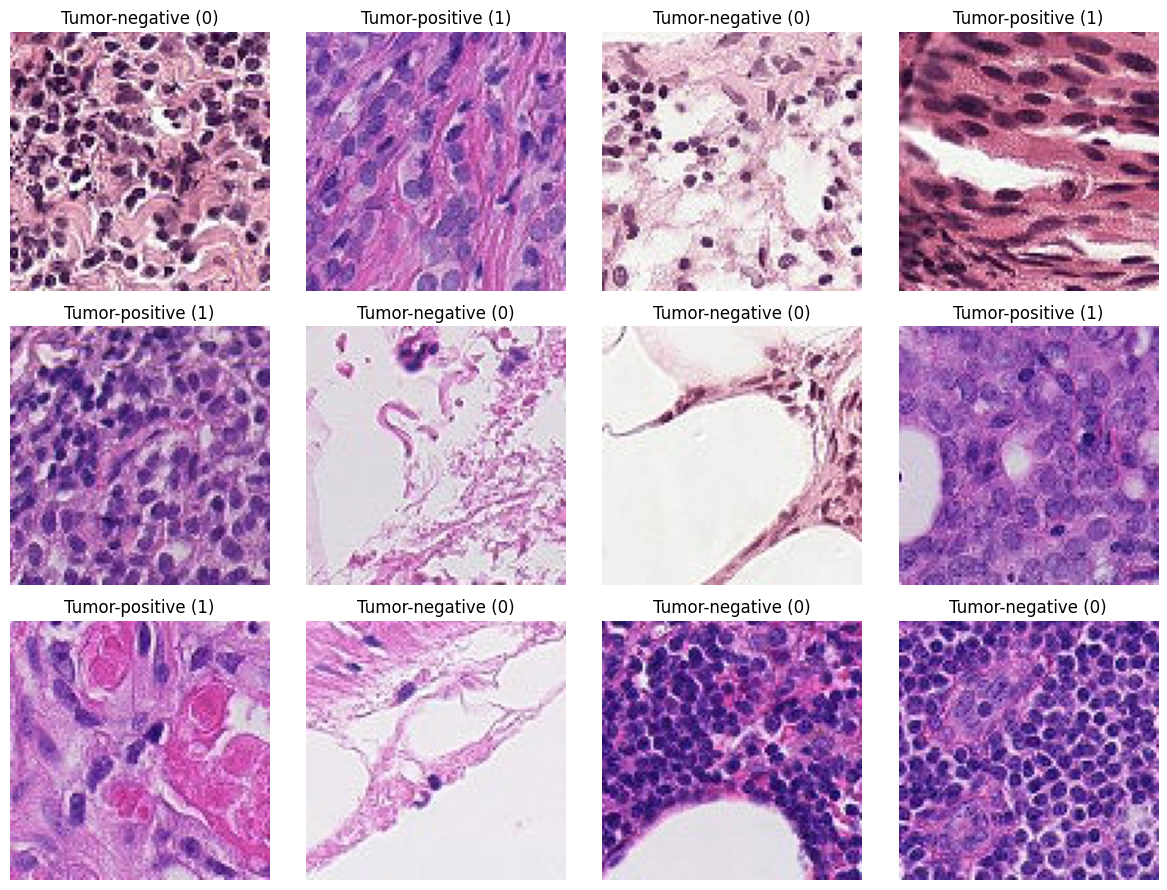

In [24]:
rng = np.random.default_rng(42)
indices = np.sort(rng.choice(262144, size=12, replace=False))

with h5py.File(x_file, "r") as fx, h5py.File(y_file, "r") as fy:
    images = fx["x"][indices]
    labels = fy["y"][indices].reshape(-1)

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i])
    label = int(labels[i])
    ax.set_title(
        "Tumor-positive (1)" if label == 1
        else "Tumor-negative (0)"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()


### Spliting the data

In [25]:
with h5py.File(y_file, "r") as f:
    all_labels = f["y"][:].reshape(-1)

rng = np.random.default_rng(42)

# Select 2,000 images
sample_indices = rng.choice(
    len(all_labels),
    size=2000,
    replace=False
)

sample_labels = all_labels[sample_indices]

# Split BEFORE training
train_idx, val_idx = train_test_split(
    sample_indices,
    test_size=0.20,
    random_state=42,
    stratify=sample_labels
)

print("Training images:", len(train_idx))
print("Validation images:", len(val_idx))

print("Overlap:", len(set(train_idx) & set(val_idx)))

Training images: 1600
Validation images: 400
Overlap: 0


### Creating the training and validation dataset

It will be use:
- Training set: 90% of the labeled data.
- Validation set: 10% to evaluate the models during development.
- Batch size: 32.

In [26]:
class PCamDataset(Dataset):

    def __init__(self, x_path, y_path, indices, transform=None):
        self.x_path = str(x_path)
        self.y_path = str(y_path)
        self.indices = np.asarray(indices)
        self.transform = transform

        self._x_file = None
        self._y_file = None

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):

        if self._x_file is None:
            self._x_file = h5py.File(self.x_path, "r")
            self._y_file = h5py.File(self.y_path, "r")

        actual_idx = int(self.indices[idx])

        image = self._x_file["x"][actual_idx]
        label = int(
            self._y_file["y"][actual_idx].reshape(-1)[0]
        )

        image = Image.fromarray(image)

        if self.transform is not None:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)

In [24]:
PCamDataset

__main__.PCamDataset

### Image Preprocessing

We'll be using ImageNet normalization because we are using pretrained weights.

In [27]:
image_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image preprocessing defined.")

Image preprocessing defined.


### Small Test Loader

We'll use only 2,000 images to test the pipeline.

In [84]:
# Small reproducible subset for pipeline testing
dataset = PCamDataset(
    x_file,
    y_file,
    train_idx,
    transform=image_transform
)

resnet_val_dataset = PCamDataset(
    x_file, y_file, val_idx, image_transform)
    
loader = DataLoader(
    resnet_val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

images, labels = next(iter(loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Image tensor device:", images.device)
print("Labels in batch:", labels.tolist()[:10])


Batch image shape: torch.Size([32, 3, 96, 96])
Batch label shape: torch.Size([32])
Image tensor device: cpu
Labels in batch: [1, 1, 1, 0, 1, 0, 0, 0, 1, 1]


### Build Model 1: ResNet-18
We'll use a pretrained ResNet-18 and replace its final classification layer with a two-class output:
- Class 0: tumor-negative
- Class 1: tumor-positive

In [85]:
weights_path = Path.home() / "Desktop" / "Untitled Folder" / "resnet18-f37072fd.pth"

assert weights_path.exists(), f"File not found: {weights_path}"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

resnet = models.resnet18(weights=None)
state_dict = torch.load(
    weights_path,
    map_location="cpu",
    weights_only=True
)
resnet.load_state_dict(state_dict)
#replace the final layer for binany classification
resnet.fc = nn.Linear(resnet.fc.in_features, 2)
resnet = resnet.to(device)

print("Pretrained weights loaded successfully.")
print("Model device:", next(resnet.parameters()).device)
print("GPU:", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")


Pretrained weights loaded successfully.
Model device: cuda:0
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


#### Optimizer

In [32]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    resnet.parameters(),
    lr=1e-4
)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)


Loss function: CrossEntropyLoss()
Optimizer: Adam


### Train for one epoch

In [86]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    start = time.time()

    for batch_images, batch_labels in loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        optimizer.zero_grad()

        outputs = model(batch_images)
        loss = criterion(outputs, batch_labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * batch_images.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == batch_labels).sum().item()
        total += batch_labels.size(0)

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.time() - start

    return {
        "loss": running_loss / total,
        "accuracy": correct / total,
        "seconds": elapsed
    }

result = train_one_epoch(
    resnet,
    loader,
    criterion,
    optimizer,
    device
)

print(f"Training loss: {result['loss']:.4f}")
print(f"Training accuracy: {result['accuracy']:.4f}")
print(f"Training time: {result['seconds']:.1f} seconds")
print("GPU:", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")


Training loss: 0.7027
Training accuracy: 0.5700
Training time: 0.8 seconds
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


### Evaluate the Model on reserved images

This creates 1,600 training examples and 400 validation examples for the pilot.Because PCam includes official predefined splits, we'll use those for the final experiment rather than relying on this random pilot split.

### Evaluation of Validation Accuracy

This measures accuracy, precision, recall, F1-score, and ROC-AUC.

In [87]:
def evaluate_model(model, loader, device):
    model.eval()
    y_true, y_pred, y_prob = [], [], []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            logits = model(images)
            probabilities = torch.softmax(logits, dim=1)[:, 1]

            y_true.extend(labels.numpy().tolist())
            y_pred.extend(logits.argmax(dim=1).cpu().numpy().tolist())
            y_prob.extend(probabilities.cpu().numpy().tolist())

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_prob)
    }

metrics = evaluate_model(resnet, loader, device)

for name, value in metrics.items():
    print(f"{name.capitalize()}: {value:.4f}")


Accuracy: 0.5275
Precision: 0.5309
Recall: 0.4322
F1: 0.4765
Roc_auc: 0.5505


### Confusion Matrix

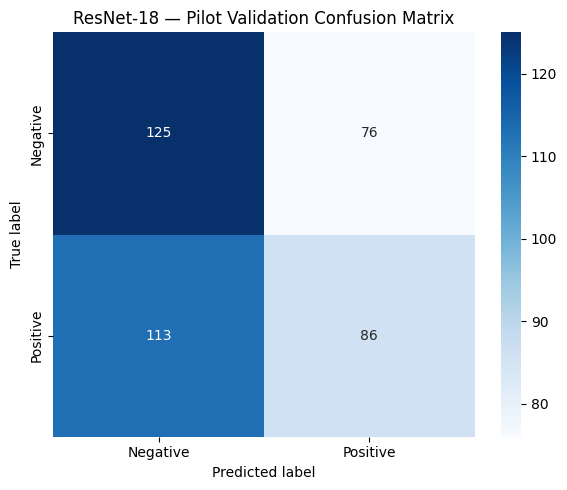

                precision    recall  f1-score   support

Tumor-negative       0.53      0.62      0.57       201
Tumor-positive       0.53      0.43      0.48       199

      accuracy                           0.53       400
     macro avg       0.53      0.53      0.52       400
  weighted avg       0.53      0.53      0.52       400



In [88]:
resnet.eval()
y_true, y_pred = [], []

with torch.no_grad():
    for images, labels in loader:
        images = images.to(device)
        predictions = resnet(images).argmax(dim=1).cpu().numpy()

        y_true.extend(labels.numpy())
        y_pred.extend(predictions)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("ResNet-18 — Pilot Validation Confusion Matrix")
plt.tight_layout()
plt.show()

print(classification_report(
    y_true,
    y_pred,
    target_names=["Tumor-negative", "Tumor-positive"],
    zero_division=0
))


### Prepare images for ViT

ViT-Base expects 224 x 224 images.

In [41]:
# ViT preprocessing
vit_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

In [43]:
# ViT datasets
vit_train_dataset = PCamDataset(
    x_file, y_file, train_idx, vit_transform
)

vit_val_dataset = PCamDataset(
    x_file, y_file, val_idx, vit_transform
)

In [93]:
# ViT loaders
vit_train_loader = DataLoader(
    vit_train_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

vit_val_loader = DataLoader(
    vit_val_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

### Model 2: Vision Transformer (ViT)

We'll now biuld a pretrained Vision Transformer, and evaluate it on the same 400 validation images. This will allow us to compare the two architectures fairly.

In [52]:
vit = ViTForImageClassification.from_pretrained(
    "google/vit-base-patch16-224",
    num_labels=2,
    ignore_mismatched_sizes=True
)

vit = vit.to(device)
print("Device:", next(vit.parameters()).device)
print("Output classes:", vit.config.num_labels)


Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224 and are newly initialized because the shapes did not match:
- classifier.bias: found shape torch.Size([1000]) in the checkpoint and torch.Size([2]) in the model instantiated
- classifier.weight: found shape torch.Size([1000, 768]) in the checkpoint and torch.Size([2, 768]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Device: cuda:0
Output classes: 2


### Optimizer

In [47]:
vit_criterion = nn.CrossEntropyLoss()

vit_optimizer = optim.AdamW(
    vit.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

print("Optimizer: AdamW")
print("Learning rate: 2e-5")
print("Batch size: 8")

Optimizer: AdamW
Learning rate: 2e-5
Batch size: 8


### ViT Train

In [94]:
def train_vit_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0
    start = time.time()

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(pixel_values=images).logits
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    if device.type == "cuda":
        torch.cuda.synchronize()

    return {
        "loss": total_loss / total,
        "accuracy": correct / total,
        "seconds": time.time() - start
    }


In [95]:
vit_result = train_vit_one_epoch(
    vit,
    vit_train_loader,
    vit_criterion,
    vit_optimizer,
    device
)

print(f"ViT training loss: {vit_result['loss']:.4f}")
print(f"ViT training accuracy: {vit_result['accuracy']:.4f}")
print(f"ViT training time: {vit_result['seconds']:.1f} seconds")


ViT training loss: 0.7151
ViT training accuracy: 0.5494
ViT training time: 33.3 seconds


### Evaluate ViT on Validation dataset

In [96]:
def evaluate_vit(model, loader, device):
    model.eval()
    y_true, y_pred, y_prob = [], [], []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            logits = model(pixel_values=images).logits
            probabilities = torch.softmax(logits, dim=1)[:, 1]
            predictions = logits.argmax(dim=1)

            y_true.extend(labels.numpy().tolist())
            y_pred.extend(predictions.cpu().numpy().tolist())
            y_prob.extend(probabilities.cpu().numpy().tolist())

    print(f"Accuracy:  {accuracy_score(y_true, y_pred):.4f}")
    print(f"Precision: {precision_score(y_true, y_pred, zero_division=0):.4f}")
    print(f"Recall:    {recall_score(y_true, y_pred, zero_division=0):.4f}")
    print(f"F1-score:  {f1_score(y_true, y_pred, zero_division=0):.4f}")
    print(f"ROC-AUC:   {roc_auc_score(y_true, y_prob):.4f}")
    print("\nClassification report:")
    print(classification_report(
        y_true, y_pred,
        target_names=["Negative", "Positive"],
        zero_division=0
    ))

evaluate_vit(vit, vit_val_loader, device)

Accuracy:  0.5375
Precision: 0.5184
Recall:    0.9899
F1-score:  0.6805
ROC-AUC:   0.6410

Classification report:
              precision    recall  f1-score   support

    Negative       0.90      0.09      0.16       201
    Positive       0.52      0.99      0.68       199

    accuracy                           0.54       400
   macro avg       0.71      0.54      0.42       400
weighted avg       0.71      0.54      0.42       400



### Evaluation in  both models
Here we are checking how well each trained model performs on the 400 unseen validation images.

In [97]:
def evaluate_model(model, loader, device, model_type):

    model.eval()

    y_true = []
    y_pred = []
    y_prob = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            if model_type == "vit":
                outputs = model(pixel_values=images).logits
            else:
                outputs = model(images)

            probabilities = torch.softmax(outputs, dim=1)[:, 1]
            predictions = outputs.argmax(dim=1)

            y_true.extend(labels.numpy().tolist())
            y_pred.extend(predictions.cpu().numpy().tolist())
            y_prob.extend(probabilities.cpu().numpy().tolist())

    metrics = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

    return metrics, y_true, y_pred, y_prob


resnet_metrics, resnet_true, resnet_pred, resnet_prob = evaluate_model(
    resnet,
    loader,
    device,
    "resnet"
)

vit_metrics, vit_true, vit_pred, vit_prob = evaluate_model(
    vit,
    vit_val_loader,
    device,
    "vit"
)

print("ResNet-18:", resnet_metrics)
print("ViT:", vit_metrics)

ResNet-18: {'Accuracy': 0.5275, 'Precision': 0.5308641975308642, 'Recall': 0.4321608040201005, 'F1-score': 0.47645429362880887, 'ROC-AUC': 0.5504637615940398}
ViT: {'Accuracy': 0.5375, 'Precision': 0.5184210526315789, 'Recall': 0.9899497487437185, 'F1-score': 0.6804835924006909, 'ROC-AUC': 0.6409660241506037}


### Create the results table

In [98]:
results = pd.DataFrame({
    "Metric": list(resnet_metrics.keys()),
    "ResNet-18": list(resnet_metrics.values()),
    "ViT": list(vit_metrics.values())
})

display(results.round(4))

results.to_csv("model_comparison_results.csv", index=False)

,Metric,ResNet-18,ViT
0,Accuracy,0.5275,0.5375
1,Precision,0.5309,0.5184
2,Recall,0.4322,0.9899
3,F1-score,0.4765,0.6805
4,ROC-AUC,0.5505,0.6410


### Plot model performance

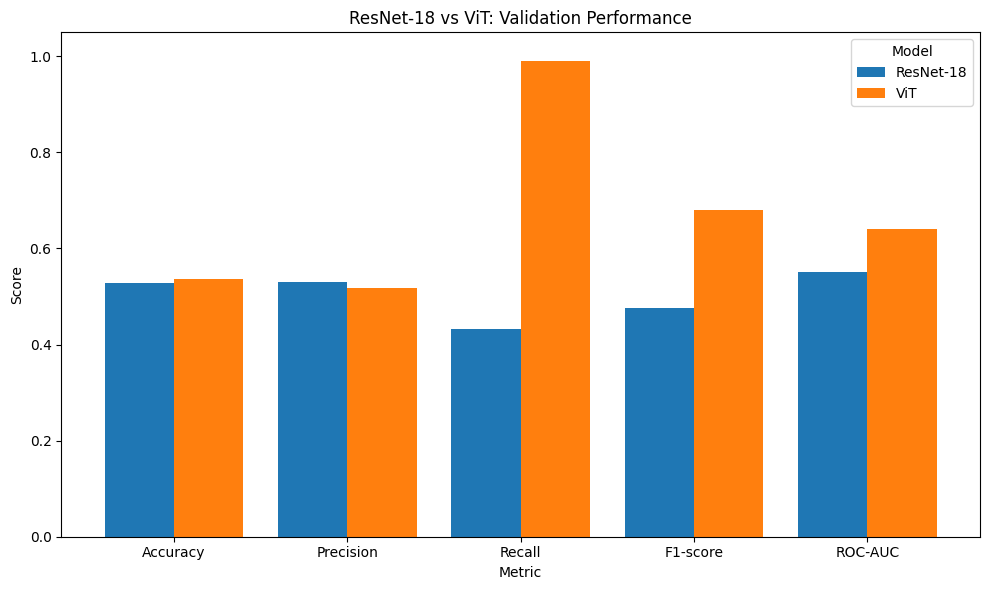

In [99]:
ax = results.set_index("Metric").plot(
    kind="bar",
    figsize=(10, 6),
    width=0.8
)

plt.title("ResNet-18 vs ViT: Validation Performance")
plt.ylabel("Score")
plt.xlabel("Metric")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title="Model")
plt.tight_layout()

plt.savefig("model_performance.png", dpi=300)
plt.show()

### Save both trained models

In [100]:
torch.save(
    resnet.state_dict(),
    "resnet18_pcam_pilot.pth"
)

vit.save_pretrained("vit_pcam_pilot")

print("Both models saved successfully")

Both models saved successfully


### Saving results

In [101]:
Path("results").mkdir(exist_ok=True)

# Save evaluation metrics
results.to_csv(
    "results/model_comparison_results.csv",
    index=False
)

# Verify that both models evaluated the same labels
assert np.array_equal(resnet_true, vit_true)

# Save individual predictions and probabilities
predictions = pd.DataFrame({
    "Image_Index": val_idx,
    "True_Label": resnet_true,
    "ResNet_Prediction": resnet_pred,
    "ResNet_Probability": resnet_prob,
    "ViT_Prediction": vit_pred,
    "ViT_Probability": vit_prob
})

predictions.to_csv(
    "results/validation_predictions.csv",
    index=False
)

print("Results saved successfully")

Results saved successfully


In [102]:
print("ResNet validation labels:", len(resnet_true))
print("ViT validation labels:", len(vit_true))

print("\nFirst 20 ResNet labels:")
print(resnet_true[:20])

print("\nFirst 20 ViT labels:")
print(vit_true[:20])

print("\nSame labels in the same order:")
print(np.array_equal(resnet_true, vit_true))

ResNet validation labels: 400
ViT validation labels: 400

First 20 ResNet labels:
[1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1]

First 20 ViT labels:
[1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1]

Same labels in the same order:
True


In [79]:
resnet_indices = np.asarray(loader.dataset.indices)
vit_indices = np.asarray(vit_val_loader.dataset.indices)

print("ResNet validation images:", len(resnet_indices))
print("ViT validation images:", len(vit_indices))

print("Same images:",
      set(resnet_indices) == set(vit_indices))

print("Same image order:",
      np.array_equal(resnet_indices, vit_indices))

print("\nResNet first 10 indices:")
print(resnet_indices[:10])

print("\nViT first 10 indices:")
print(vit_indices[:10])

ResNet validation images: 400
ViT validation images: 400
Same images: True
Same image order: True

ResNet first 10 indices:
[142428 172735  63233 129025 234589  47736  27565  44781 170369 147639]

ViT first 10 indices:
[142428 172735  63233 129025 234589  47736  27565  44781 170369 147639]


In [80]:
resnet_val_loader = DataLoader(
    resnet_val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

vit_val_loader = DataLoader(
    vit_val_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

In [81]:
resnet_metrics, resnet_true, resnet_pred, resnet_prob = evaluate_model(
    resnet,
    resnet_val_loader,
    device,
    "resnet"
)

vit_metrics, vit_true, vit_pred, vit_prob = evaluate_model(
    vit,
    vit_val_loader,
    device,
    "vit"
)

print("ResNet-18:", resnet_metrics)
print("ViT:", vit_metrics)

ResNet-18: {'Accuracy': 0.9, 'Precision': 0.8878048780487805, 'Recall': 0.914572864321608, 'F1-score': 0.900990099009901, 'ROC-AUC': 0.9666741668541714}
ViT: {'Accuracy': 0.5375, 'Precision': 0.5184210526315789, 'Recall': 0.9899497487437185, 'F1-score': 0.6804835924006909, 'ROC-AUC': 0.6409660241506037}


In [82]:
print("Same labels:", np.array_equal(resnet_true, vit_true))

print("Same image order:", np.array_equal(
    resnet_val_loader.dataset.indices,
    vit_val_loader.dataset.indices
))

Same labels: True
Same image order: True
